# Busca exaustiva de duplicidades na canonização

**Objetivo.** Encontrar automaticamente duas árvores unárias/binárias distintas que representam a mesma função e recebem saídas canônicas diferentes. Este notebook audita as **três implementações locais** do [notebook comparativo](00_canonicalization_comparison.ipynb): CCBL, normalização polinomial restrita inspirada em SimpliPy/Flash-ANSR e chave AC do fluxo Verifier-Guided. A etapa de rollout também é examinada separadamente.

Uma duplicidade exige simultaneamente:
\[
A\ne B,\qquad f_A(x)=f_B(x)\ \text{para todo }x\in\mathbb R^m,\qquad C(A)\ne C(B).
\]
A primeira diferença é sintática; a igualdade intermediária é algébrica; a última compara as saídas reais dos métodos. O domínio contém todos os estados reais dos lags indicados, independentemente de uma trajetória particular.

**Exaustivo dentro de um espaço declarado.** Enumeramos todas as árvores ordenadas de cada tamanho, sem sorteio e sem canonizar previamente. Cada método para em seu primeiro contraexemplo; os demais continuam até o tamanho máximo. A expressão “nenhum encontrado” descreve a cobertura finita. As três implementações são adaptações do projeto, portanto os resultados se referem a estes arquivos de código.

**Convenção.** \(x=X_0(t-1)\), \(y=X_0(t-2)\). Na busca simbólica, os slots \(\ell_1,\ell_2\) permanecem átomos distintos. Nas buscas com valores fixos, os bindings estão explícitos. Aritmética exata define a identidade; ponto flutuante é discutido no teste de rollout.

In [1]:
from __future__ import annotations

from collections import Counter
from functools import partial
from hashlib import sha256
from importlib import metadata
from importlib.util import module_from_spec, spec_from_file_location
from pathlib import Path
from time import perf_counter
import platform
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd
import sympy as sp
from IPython.display import Markdown, display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "src" / "tsfmxai").is_dir())
sys.path.insert(0, str(ROOT / "src"))

from tsfmxai.evaluation.canonicalization_audit import (
    enumerate_ordered_trees, exact_expression, search_first_counterexamples,
)
from tsfmxai.representations.expression import (
    Add, Multiply, Tanh, Lag, Parameter, Time, children, walk,
    operator_count, node_count, to_skeleton_formula,
)

METHOD_PATHS = {
    "CCBL": "experiments/canonicalization/binary_local_commutative/canonicalizer.py",
    "Polinomial restrito": "experiments/canonicalization/simplipy_flash_ansr/canonicalizer.py",
    "Verifier AC": "experiments/canonicalization/verifier_guided/canonicalizer.py",
}

def load_snapshot(name, relative_path):
    spec = spec_from_file_location(name, ROOT / relative_path)
    module = module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module

modules = {label: load_snapshot(f"audit_method_{i}", path)
           for i, (label, path) in enumerate(METHOD_PATHS.items())}
ccbl, poly, verifier = (modules[name] for name in METHOD_PATHS)
METHODS = {label: module.canonical_key for label, module in modules.items()}
print(f"Python {platform.python_version()} | SymPy {sp.__version__}")
display(pd.DataFrame([{"Método": k, "Código avaliado": v} for k, v in METHOD_PATHS.items()]))

Python 3.11.9 | SymPy 1.14.0


,Método,Código avaliado
0,CCBL,experiments/canonicalization/binary_local_comm...
1,Polinomial restrito,experiments/canonicalization/simplipy_flash_an...
2,Verifier AC,experiments/canonicalization/verifier_guided/c...


**O que a célula fez.** Carregou os métodos existentes sem alterá-los e importou o enumerador reutilizável. O oráculo algébrico usa SymPy independentemente dos três métodos avaliados; suas dependências são registradas no final.

## 1. Como a busca visita todas as árvores

Com \(L\) folhas, \(U\) operadores unários e \(B\) operadores binários, o número de árvores com exatamente \(n\) operadores é:
\[
N_0=L,\qquad N_n=U\,N_{n-1}+B\sum_{i=0}^{n-1}N_iN_{n-1-i}.
\]
Para cada raiz binária, visitamos todas as divisões de orçamento entre esquerda e direita e todos os pares de subárvores. Assim, permutações e parentizações diferentes entram separadamente.

~~~text
para n = 0, 1, ..., tamanho máximo:
    enumerar todas as árvores ordenadas com n operadores
    para cada árvore elegível T:
        identidade = oráculo algébrico exato(T)
        para cada método que ainda procura um contraexemplo:
            saída = método(T)
            se já existe A com a mesma identidade e outra saída:
                guardar (A, T), as duas saídas e a posição da descoberta
                parar apenas este método
            senão: guardar um representante desta identidade
    parar a busca se todos os métodos encontraram um contraexemplo
~~~

Implementação: [canonicalization_audit.py](../../src/tsfmxai/evaluation/canonicalization_audit.py), funções **enumerate_ordered_trees**, **exact_expression** e **search_first_counterexamples**. A tabela de consulta guarda expressões exatas, com comparação de igualdade, em vez de decidir identidade por hash ou amostras numéricas.

**Limites científicos.** Oráculos iguais constituem uma identidade reconhecida. Oráculos diferentes podem esconder outras identidades analíticas. Além disso, unicidade e preservação de significado são propriedades separadas: devolver uma chave constante passaria um teste de duplicidade, mas descartaria a função. Aqui procuramos falhas de unicidade nas implementações já existentes.

In [2]:
x, y = Lag(0, "l1"), Lag(0, "l2")
two, minus_one = Parameter("two"), Parameter("minus_one")

CONFIG = {
    "A — simbólico": {
        "leaves": (x, y), "binary": (Add, Multiply), "unary": (Tanh,),
        "max_operators": 3, "parameter_values": {}, "lag_values": {},
        "analytic_tanh": False, "require_tanh": False,
    },
    "B — constante fixada": {
        "leaves": (x, two), "binary": (Add, Multiply), "unary": (),
        "max_operators": 2, "parameter_values": {"two": 2}, "lag_values": {"l1": 1},
        "analytic_tanh": False, "require_tanh": False,
    },
    "C — identidade unária": {
        "leaves": (x, minus_one), "binary": (Multiply,), "unary": (Tanh,),
        "max_operators": 3, "parameter_values": {"minus_one": -1}, "lag_values": {"l1": 1},
        "analytic_tanh": True, "require_tanh": True,
    },
}

def expected_layers(config):
    counts = [len(config["leaves"])]
    for n in range(1, config["max_operators"] + 1):
        counts.append(len(config["unary"]) * counts[n - 1] +
                      len(config["binary"]) * sum(counts[i] * counts[n - 1 - i]
                                                  for i in range(n)))
    return counts

coverage = []
for scenario, config in CONFIG.items():
    counts = expected_layers(config)
    coverage.append({
        "Cenário": scenario, "Folhas": ", ".join(map(to_skeleton_formula, config["leaves"])),
        "Binários": ", ".join(op.__name__ for op in config["binary"]),
        "Unários": ", ".join(op.__name__ for op in config["unary"]) or "—",
        "Máx. operadores": config["max_operators"],
        "Árvores por camada": counts, "Universo completo": sum(counts),
    })
display(pd.DataFrame(coverage).set_index("Cenário"))

full_a = list(enumerate_ordered_trees(
    CONFIG["A — simbólico"]["leaves"], max_operators=3))
assert [Counter(map(operator_count, full_a))[n] for n in range(4)] == expected_layers(CONFIG["A — simbólico"])
assert len(set(full_a)) == len(full_a) == 1112
del full_a
print("Cobertura do cenário A: 1.112 árvores distintas, com 0 a 3 operadores.")

,Folhas,Binários,Unários,Máx. operadores,Árvores por camada,Universo completo
Cenário,,,,,,
A — simbólico,"LAG(0, l1), LAG(0, l2)","Add, Multiply",Tanh,3,"[2, 10, 90, 1010]",1112
B — constante fixada,"LAG(0, l1), two","Add, Multiply",—,2,"[2, 8, 64]",74
C — identidade unária,"LAG(0, l1), minus_one",Multiply,Tanh,3,"[2, 6, 30, 186]",224


Cobertura do cenário A: 1.112 árvores distintas, com 0 a 3 operadores.


**O que a célula fez.** Declarou três universos finitos e verificou a contagem da enumeração. A inclui `tanh` como função opaca; B fixa `two=2`; C usa a propriedade de função ímpar de `tanh` com `minus_one=-1`. Todas as buscas exigem a presença de um lag, evitando exemplos que sejam apenas constantes.

## 2. Executar a busca e registrar o primeiro contraexemplo

No cenário A, associatividade, comutatividade e distributividade são reconhecidas pelo oráculo; **tanh** permanece uma função opaca com argumento normalizado. Isso permite auditar a garantia polinomial declarada pelo método.

No cenário B, comparamos **mecanismos instanciados**: valores numéricos fazem parte da função. Os métodos recebem somente a AST, conforme suas interfaces atuais. Uma falha aqui delimita a interface simbólica em relação à equivalência com bindings.

No cenário C, ambas as árvores precisam conter um lag e **tanh**. A identidade \(\tanh(-x)=-\tanh(x)\) é válida para todo \(x\) real. A busca enumera as árvores; nenhum par de contraexemplo é fornecido manualmente.

In [3]:
results, oracles, durations = {}, {}, {}
for scenario, config in CONFIG.items():
    oracle = partial(exact_expression,
                     parameter_values=config["parameter_values"],
                     lag_values=config["lag_values"],
                     analytic_tanh=config["analytic_tanh"])
    oracles[scenario] = oracle
    def eligible(tree, require_tanh=config["require_tanh"]):
        nodes = tuple(walk(tree))
        return (any(isinstance(node, Lag) for node in nodes) and
                (not require_tanh or any(isinstance(node, Tanh) for node in nodes)))
    started = perf_counter()
    results[scenario] = search_first_counterexamples(
        enumerate_ordered_trees(
            config["leaves"], max_operators=config["max_operators"],
            binary=config["binary"], unary=config["unary"]),
        methods=METHODS, oracle=oracle, eligible=eligible)
    durations[scenario] = perf_counter() - started

rows = []
for scenario, result in results.items():
    for method in METHODS:
        witness = result.counterexamples.get(method)
        rows.append({
            "Cenário": scenario, "Método": method,
            "Resultado": "Contraexemplo encontrado" if witness else "Nenhum no limite testado",
            "Chamadas ao método": result.tested_by_method[method],
            "Camada na descoberta": witness.operator_layer if witness else None,
            "Prefixo visitado": witness.visited_at_discovery if witness else result.visited,
            "Erros de execução": result.errors_by_method[method],
        })
summary = pd.DataFrame(rows)
display(summary.set_index(["Cenário", "Método"]))
display(pd.DataFrame([
    {"Cenário": scenario, "Universo": sum(expected_layers(CONFIG[scenario])),
     "Árvores visitadas": result.visited, "Elegíveis": result.eligible,
     "Parada": result.stop_reason, "Tempo total (s)": durations[scenario]}
    for scenario, result in results.items()
]).set_index("Cenário"))

assert not results["A — simbólico"].errors_by_method["Polinomial restrito"]
assert results["A — simbólico"].visited == 1112
assert "Polinomial restrito" not in results["A — simbólico"].counterexamples
assert {"CCBL", "Verifier AC"} <= results["A — simbólico"].counterexamples.keys()
assert all(len(results[s].counterexamples) == 3 for s in ("B — constante fixada", "C — identidade unária"))
assert all(not any(result.errors_by_method.values()) for result in results.values())

Resultado  \
Cenário               Método                                          
A — simbólico         CCBL                 Contraexemplo encontrado   
                      Polinomial restrito  Nenhum no limite testado   
                      Verifier AC          Contraexemplo encontrado   
B — constante fixada  CCBL                 Contraexemplo encontrado   
                      Polinomial restrito  Contraexemplo encontrado   
                      Verifier AC          Contraexemplo encontrado   
C — identidade unária CCBL                 Contraexemplo encontrado   
                      Polinomial restrito  Contraexemplo encontrado   
                      Verifier AC          Contraexemplo encontrado   

                                           Chamadas ao método  \
Cenário               Método                                    
A — simbólico         CCBL                                375   
                      Polinomial restrito                1112   
                      Verifier AC                          75   
B — constante fixada  CCBL                                  6   
                      Polinomial restrito                   6   
                      Verifier AC                           6   
C — identidade unária CCBL                                  8   
                      Polinomial restrito                   8   
                      Verifier AC                           8   

                                           Camada na descoberta  \
Cenário               Método                                      
A — simbólico         CCBL                                  3.0   
                      Polinomial restrito                   NaN   
                      Verifier AC                           2.0   
B — constante fixada  CCBL                                  1.0   
                      Polinomial restrito                   1.0   
                      Verifier AC                           1.0   
C — identidade unária CCBL                                  2.0   
                      Polinomial restrito                   2.0   
                      Verifier AC                           2.0   

                                           Prefixo visitado  Erros de execução  
Cenário               Método                                                    
A — simbólico         CCBL                              375                  0  
                      Polinomial restrito              1112                  0  
                      Verifier AC                        75                  0  
B — constante fixada  CCBL                                8                  0  
                      Polinomial restrito                 8                  0  
                      Verifier AC                         8                  0  
C — identidade unária CCBL                               21                  0  
                      Polinomial restrito                21                  0  
                      Verifier AC                        21                  0

,Universo,Árvores visitadas,Elegíveis,Parada,Tempo total (s)
Cenário,,,,,
A — simbólico,1112,1112,1112,size_bound_exhausted,0.192651
B — constante fixada,74,8,6,all_methods_found,0.000965
C — identidade unária,224,21,8,all_methods_found,0.004373


**O que a célula fez.** Executou as buscas, guardou o primeiro par por método e contou chamadas, cobertura e erros separadamente. O prefixo é a posição na enumeração ordenada; ele pode incluir árvores filtradas. A minimalidade é relativa a essa gramática e ordem de busca, por número máximo de operadores do par.

## 3. Inspecionar os contraexemplos descobertos

As fórmulas, diferenças algébricas e saídas abaixo vêm dos pares encontrados pela busca. A CCBL renomeia slots em pré-ordem: sua saída exibida é um esqueleto estrutural. A prova de identidade usa as árvores de entrada com seus bindings; executar o esqueleto renomeado exigiria remapear esses bindings.

In [4]:
def readable(expr):
    replacements = {}
    for symbol in expr.free_symbols:
        name = str(symbol)
        replacements[symbol] = sp.Symbol({
            "lag:0:slot:l1": "x", "lag:0:slot:l2": "y",
            "lag:0:delay:1": "x", "lag:0:delay:2": "y",
        }.get(name, name), real=True)
    return sp.sstr(expr.xreplace(replacements))

for scenario, result in results.items():
    display(Markdown(f"### {scenario}"))
    for method, witness in result.counterexamples.items():
        difference = sp.expand(oracles[scenario](witness.left) - oracles[scenario](witness.right))
        assert difference == 0
        assert witness.left != witness.right
        assert METHODS[method](witness.left) == witness.left_key
        assert METHODS[method](witness.right) == witness.right_key
        assert witness.left_key != witness.right_key
        display(Markdown(f"**{method}** — identidade exata: **{readable(witness.oracle_key)}**"))
        print("Entrada A:", to_skeleton_formula(witness.left))
        print("Entrada B:", to_skeleton_formula(witness.right))
        print("Diferença algébrica A − B =", difference)
        print("Saída canônica A:", witness.left_key)
        print("Saída canônica B:", witness.right_key)
        print("Mesma fórmula, duas saídas:", witness.left_key != witness.right_key)
    if "Polinomial restrito" not in result.counterexamples:
        print("Polinomial restrito: nenhum contraexemplo nas 1.112 árvores do cenário simbólico.")

### A — simbólico

**Verifier AC** — identidade exata: **2*x*y**

Entrada A: (LAG(0, l1) * (LAG(0, l2) + LAG(0, l2)))
Entrada B: (LAG(0, l2) * (LAG(0, l1) + LAG(0, l1)))
Diferença algébrica A − B = 0
Saída canônica A: MUL(ADD(LAG[0,l2],LAG[0,l2]),LAG[0,l1])
Saída canônica B: MUL(ADD(LAG[0,l1],LAG[0,l1]),LAG[0,l2])
Mesma fórmula, duas saídas: True


**CCBL** — identidade exata: **2*x + Tanh_opaque(x)**

Entrada A: (LAG(0, l1) + (LAG(0, l1) + tanh(LAG(0, l1))))
Entrada B: (tanh(LAG(0, l1)) + (LAG(0, l1) + LAG(0, l1)))
Diferença algébrica A − B = 0
Saída canônica A: ((LAG(0, L0) + tanh(LAG(0, L1))) + LAG(0, L2))
Saída canônica B: ((LAG(0, L0) + LAG(0, L1)) + tanh(LAG(0, L2)))
Mesma fórmula, duas saídas: True
Polinomial restrito: nenhum contraexemplo nas 1.112 árvores do cenário simbólico.


...

Entrada A: tanh((LAG(0, l1) * minus_one))
Entrada B: (minus_one * tanh(LAG(0, l1)))
Diferença algébrica A − B = 0
Saída canônica A: tanh((LAG(0, L0) * P0))
Saída canônica B: (P0 * tanh(LAG(0, L0)))
Mesma fórmula, duas saídas: True


**Polinomial restrito** — identidade exata: **-tanh(x)**

Entrada A: tanh((LAG(0, l1) * minus_one))
Entrada B: (minus_one * tanh(LAG(0, l1)))
Diferença algébrica A − B = 0
Saída canônica A: ADD(MUL(TANH[ADD(MUL(LAG[0,l1],PARAMETER[minus_one]))]))
Saída canônica B: ADD(MUL(PARAMETER[minus_one],TANH[ADD(MUL(LAG[0,l1]))]))
Mesma fórmula, duas saídas: True


**Verifier AC** — identidade exata: **-tanh(x)**

Entrada A: tanh((LAG(0, l1) * minus_one))
Entrada B: (minus_one * tanh(LAG(0, l1)))
Diferença algébrica A − B = 0
Saída canônica A: TANH(MUL(LAG[0,l1],PARAMETER[minus_one]))
Saída canônica B: MUL(PARAMETER[minus_one],TANH(LAG[0,l1]))
Mesma fórmula, duas saídas: True


**O que a célula fez.** Recalculou a prova algébrica e cada saída canônica. No cenário simbólico, os pares evidenciam reagrupamento e fatoração; com `two=2`, a soma repetida equivale ao produto; com `minus_one=-1`, a paridade de `tanh` fornece uma identidade envolvendo um operador unário.

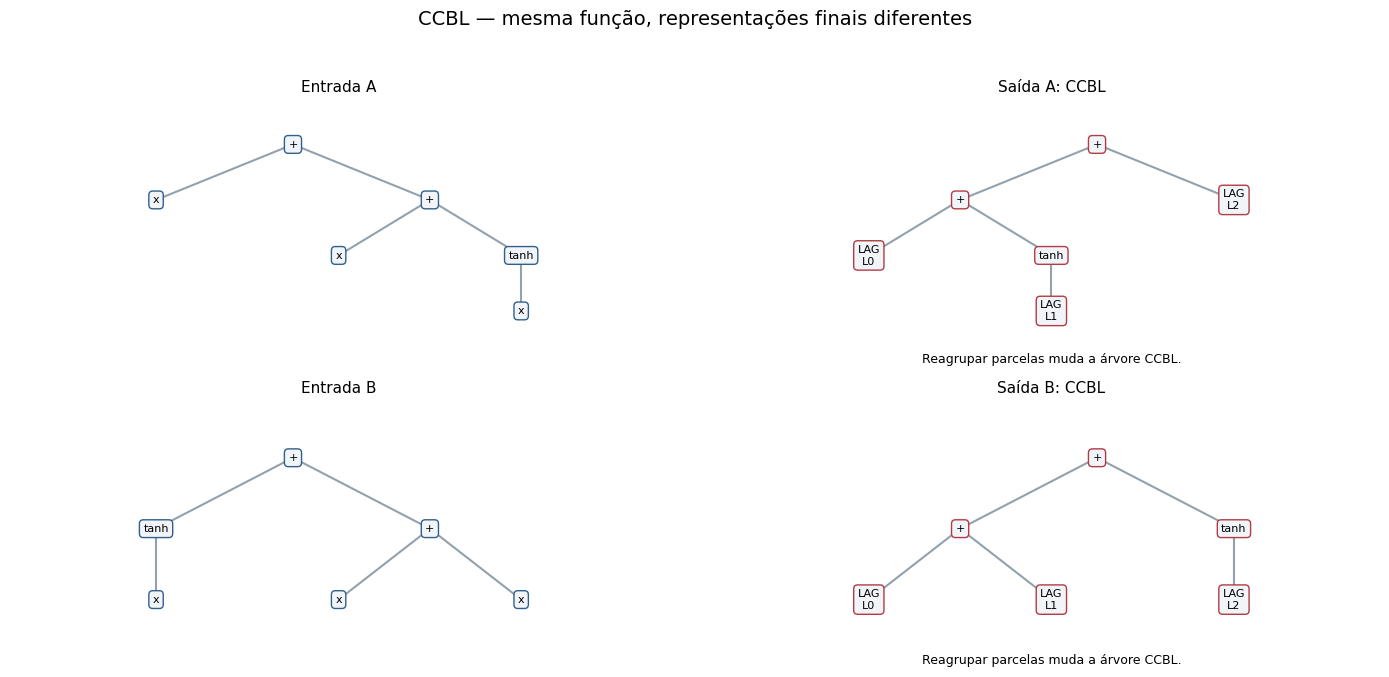

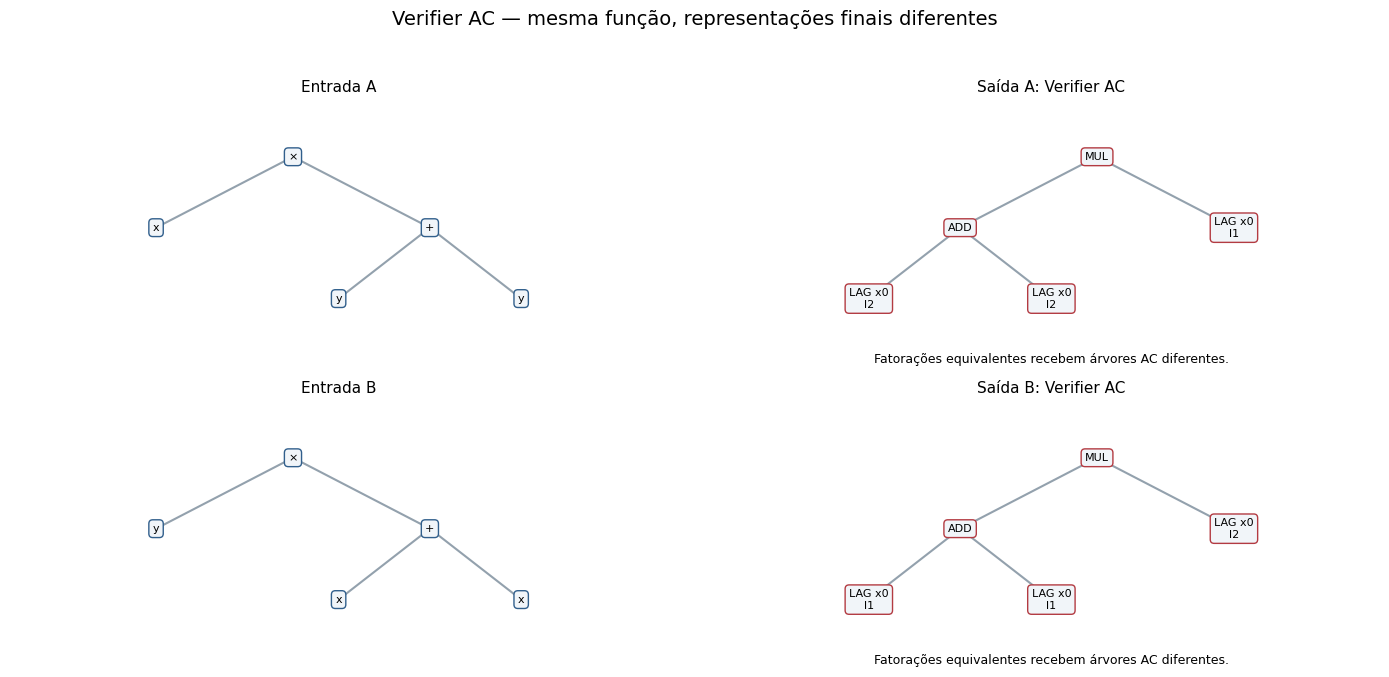

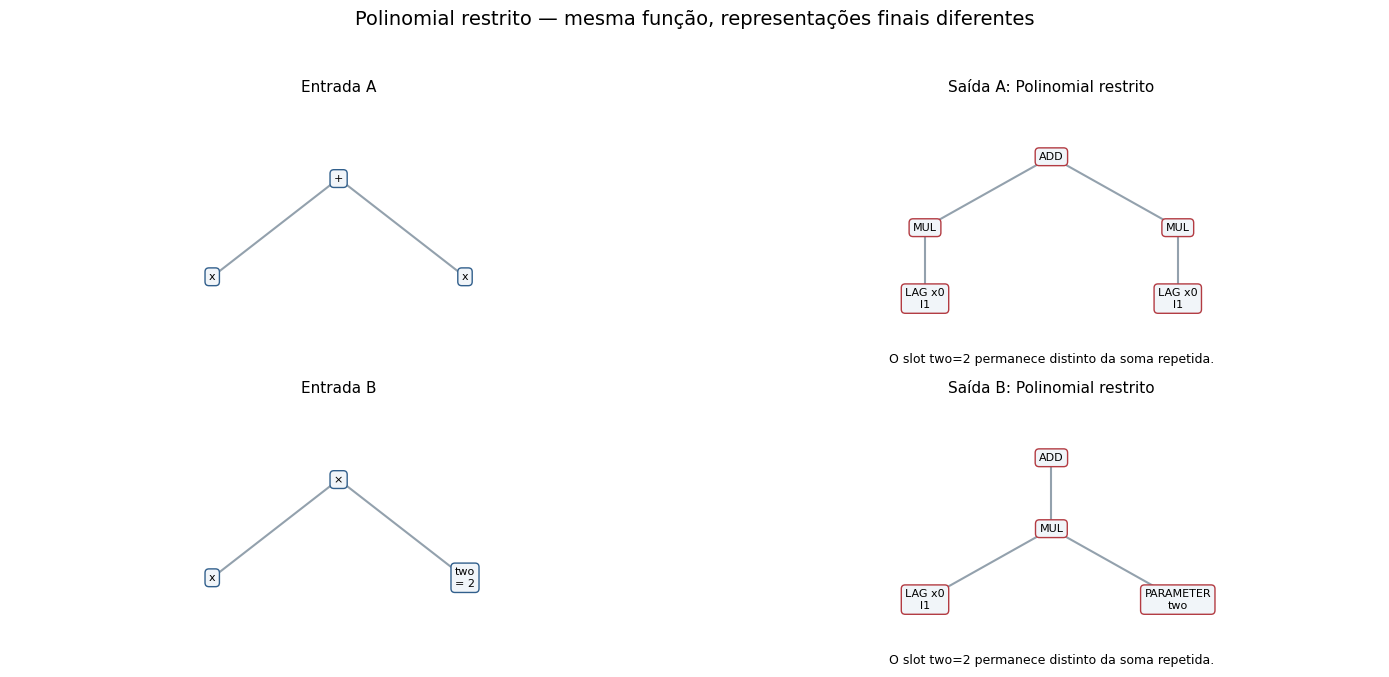

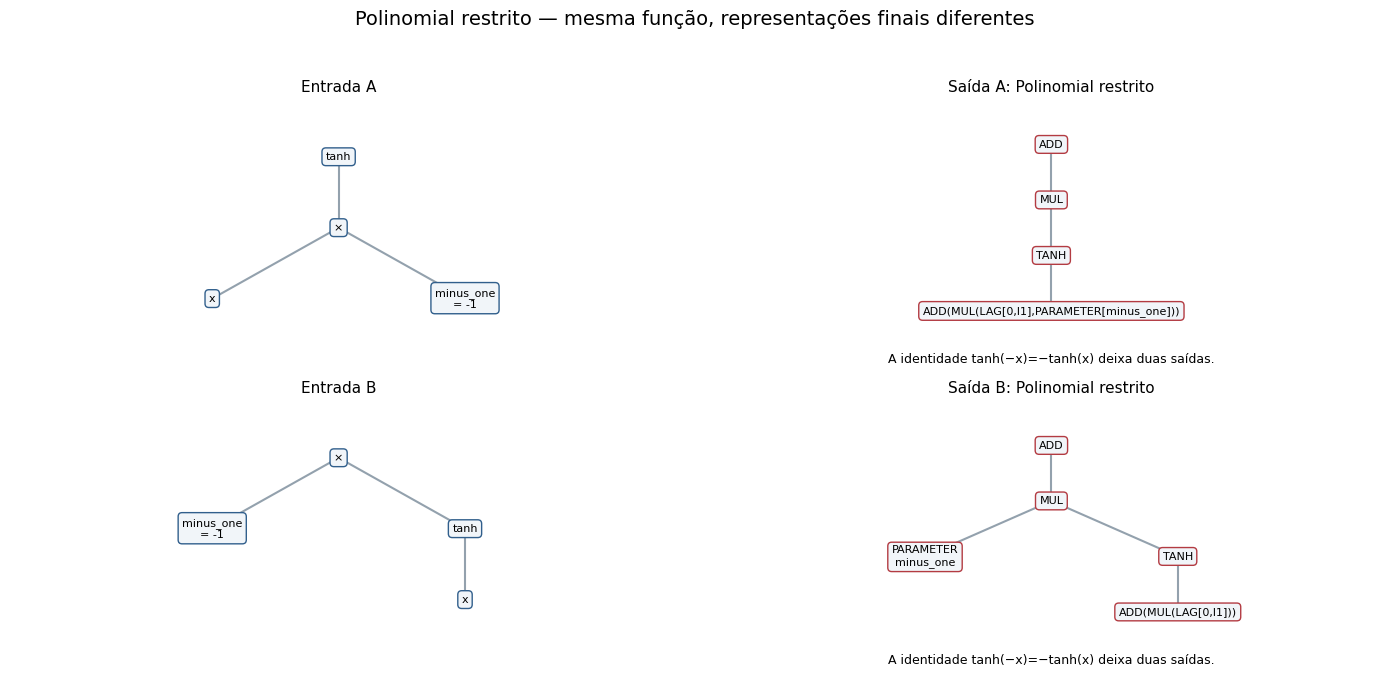

In [5]:
# Cada ocorrência na árvore recebe uma posição, mesmo com folhas repetidas.
def tree_parts(tree, bindings=None):
    bindings = bindings or {}
    if isinstance(tree, tuple):
        return tree[0], tree[1]
    if isinstance(tree, Add):
        return "+", (tree.left, tree.right)
    if isinstance(tree, Multiply):
        return "×", (tree.left, tree.right)
    if isinstance(tree, Tanh):
        return "tanh", (tree.operand,)
    if isinstance(tree, Lag):
        return {"l1": "x", "l2": "y"}.get(tree.slot, f"LAG\n{tree.slot}"), ()
    if isinstance(tree, Parameter):
        return f"{tree.slot}\n= {bindings[tree.slot]}" if tree.slot in bindings else tree.slot, ()
    return "t", ()

def draw_tree(axis, tree, title, bindings=None, color="#315f8c"):
    positions, labels, edges = {}, {}, []
    leaf_index = 0
    def visit(node, path=(), depth=0):
        nonlocal leaf_index
        label, child_nodes = tree_parts(node, bindings)
        labels[path] = label
        child_x = []
        for i, child in enumerate(child_nodes):
            child_path = path + (i,)
            edges.append((path, child_path))
            child_x.append(visit(child, child_path, depth + 1))
        if child_x:
            x_pos = sum(child_x) / len(child_x)
        else:
            x_pos = leaf_index
            leaf_index += 1
        positions[path] = (x_pos, -depth)
        return x_pos
    visit(tree)
    for parent, child in edges:
        axis.plot([positions[parent][0], positions[child][0]],
                  [positions[parent][1], positions[child][1]], color="#93a1ad", zorder=1)
    for path, label in labels.items():
        axis.text(*positions[path], label, ha="center", va="center", fontsize=8,
                  bbox=dict(boxstyle="round,pad=0.35", fc="#f1f5f9", ec=color), zorder=2)
    xs, ys = zip(*positions.values())
    axis.set(xlim=(min(xs) - 0.8, max(xs) + 0.8), ylim=(min(ys) - 0.8, 0.8))
    axis.set_title(title, fontsize=11)
    axis.axis("off")

TRANSFORMS = {"CCBL": ccbl.canonicalize,
              "Polinomial restrito": poly.canonical_structure,
              "Verifier AC": verifier.canonical_structure}
SELECTED = [
    ("A — simbólico", "CCBL", "Reagrupar parcelas muda a árvore CCBL."),
    ("A — simbólico", "Verifier AC", "Fatorações equivalentes recebem árvores AC diferentes."),
    ("B — constante fixada", "Polinomial restrito", "O slot two=2 permanece distinto da soma repetida."),
    ("C — identidade unária", "Polinomial restrito", "A identidade tanh(−x)=−tanh(x) deixa duas saídas."),
]
for scenario, method, caption in SELECTED:
    witness = results[scenario].counterexamples[method]
    fig, axes = plt.subplots(2, 2, figsize=(14, 7))
    for row, (label, tree) in enumerate((("A", witness.left), ("B", witness.right))):
        draw_tree(axes[row, 0], tree, f"Entrada {label}",
                  CONFIG[scenario]["parameter_values"])
        draw_tree(axes[row, 1], TRANSFORMS[method](tree), f"Saída {label}: {method}",
                  color="#b33b42")
        axes[row, 1].text(0.5, -0.03, caption, transform=axes[row, 1].transAxes,
                         ha="center", fontsize=9)
    fig.suptitle(f"{method} — mesma função, representações finais diferentes", fontsize=14)
    fig.tight_layout(rect=(0, 0.02, 1, 0.95), w_pad=4)
    plt.show()

**O que a célula fez.** Desenhou as entradas e saídas de quatro pares descobertos. As legendas resumem a diferença em uma linha. As duas primeiras figuras tratam de equivalência com slots simbólicos; as seguintes acrescentam valores fixos e uma identidade analítica.

## 4. O fluxo completo Verifier-Guided e o ponto flutuante

A chave AC é a primeira etapa. O código existente também pode reunir candidatos com assinaturas de rollout iguais. Vamos verificar o que essa segunda etapa faz com o contraexemplo encontrado automaticamente.

Em seguida, um **teste dirigido, separado da enumeração**, examina arredondamento em ponto flutuante. Em aritmética exata,
\[
(x+10^{16})-10^{16}=x.
\]
No avaliador de ponto flutuante, somar um valor pequeno a \(10^{16}\) pode perdê-lo antes da subtração. Isso pode separar duas fórmulas matematicamente iguais. A identidade exata e o comportamento computacional são registrados separadamente.

In [6]:
ROLLOUT_CONFIG = {
    "initial_conditions": ((0.05, 0.10), (-0.10, 0.03), (0.20, -0.05)),
    "steps": 12, "decimals": 10,
}
w = results["A — simbólico"].counterexamples["Verifier AC"]
candidates = [verifier.Candidate(label, tree, {}, {"l1": 1, "l2": 2})
              for label, tree in (("A", w.left), ("B", w.right))]
pooled = verifier.deduplicate_candidates(candidates, **ROLLOUT_CONFIG)
assert len(pooled.symbolic_representatives) == 2
assert len(pooled.behavioral_representatives) == 1

large_tree = Add(Add(x, Parameter("large")), Parameter("negative_large"))
small_tree = x
large_binding = {"large": 10**16, "negative_large": -(10**16)}
oracle_roundoff = partial(exact_expression, parameter_values=large_binding, lag_values={"l1": 1})
assert oracle_roundoff(large_tree) == oracle_roundoff(small_tree)
roundoff_candidates = [
    verifier.Candidate("cancelamento", large_tree, large_binding, {"l1": 1}),
    verifier.Candidate("x", small_tree, large_binding, {"l1": 1}),
]
roundoff = verifier.deduplicate_candidates(
    roundoff_candidates, initial_conditions=((1.0,),), steps=3, decimals=10)
assert len(roundoff.behavioral_representatives) == 2
roundoff_signatures = {
    candidate.label: verifier.rollout_signature(
        candidate.expression, parameter_values=candidate.parameter_values,
        lag_values=candidate.lag_values, initial_conditions=((1.0,),), steps=3, decimals=10)
    for candidate in roundoff_candidates
}
display(pd.DataFrame([
    {"Caso": "Par encontrado por enumeração", "Grupos AC": 2,
     "Grupos após rollout": len(pooled.behavioral_representatives),
     "Interpretação": "Rollout reúne a identidade que a chave AC separou."},
    {"Caso": "Teste dirigido: cancelamento numérico", "Grupos AC": 2,
     "Grupos após rollout": len(roundoff.behavioral_representatives),
     "Interpretação": "Arredondamento separa duas fórmulas iguais sobre os reais."},
]))
print("Assinaturas do teste dirigido:", roundoff_signatures)
print("Aritmética exata: (x + 10**16) - 10**16 = x, para todo x real.")

,Caso,Grupos AC,Grupos após rollout,Interpretação
0,Par encontrado por enumeração,2,1,Rollout reúne a identidade que a chave AC sepa...
1,Teste dirigido: cancelamento numérico,2,2,Arredondamento separa duas fórmulas iguais sob...


Assinaturas do teste dirigido: {'cancelamento': (0.0, 0.0, 0.0, '|'), 'x': (1.0, 1.0, 1.0, '|')}
Aritmética exata: (x + 10**16) - 10**16 = x, para todo x real.


**O que a célula fez.** Avaliou as duas etapas do fluxo. O rollout corrigiu a duplicidade AC do par descoberto; o teste dirigido mostrou uma separação causada por aritmética finita. As assinaturas são evidência computacional condicionada ao avaliador, estados iniciais, horizonte e arredondamento.

## 5. Conclusões e registro completo do experimento

A busca preserva a arquitetura **árvore amostrada → normalização → alvo de treinamento**. Os resultados indicam quais equivalências cada representação consegue reunir e ajudam a definir o significado do alvo.

- **CCBL:** a ordenação local deixa duplicidades decorrentes de reagrupamento.
- **Verifier AC:** a normalização associativo-comutativa ainda separa certas fatorações equivalentes; a etapa de rollout pode reuni-las, dependendo da execução.
- **Polinomial restrito:** o cenário simbólico terminou sem contraexemplo; os cenários com constantes fixadas e identidade de tanh mostram os limites de tratar parâmetros e funções como átomos.
- **Próximo critério de projeto:** declarar se o alvo representa a estrutura parametrizada ou a equação já instanciada. Comparar x+x com p*x depende de fixar p=2.
- **Alcance:** este teste busca duplicidades; uma auditoria completa também verifica preservação semântica e falsas fusões. Sua cobertura finita e o oráculo de identidades reconhecidas delimitam as conclusões.

O registro abaixo reúne configuração, código-fonte, versões, sementes, métricas e reprodução no próprio notebook. A enumeração determinística dispensa aleatoriedade e dados externos.

In [7]:
SOURCE_PATHS = [
    *METHOD_PATHS.values(),
    "src/tsfmxai/evaluation/canonicalization_audit.py",
    "src/tsfmxai/representations/expression.py",
    "tests/unit/test_canonicalization_audit.py",
]
def git_output(*args):
    return subprocess.check_output(["git", *args], cwd=ROOT, text=True).strip()

serializable_config = {
    scenario: {
        **{k: v for k, v in config.items() if k not in ("leaves", "binary", "unary")},
        "leaves": [to_skeleton_formula(leaf) for leaf in config["leaves"]],
        "binary": [op.__name__ for op in config["binary"]],
        "unary": [op.__name__ for op in config["unary"]],
        "requires_lag": True,
    } for scenario, config in CONFIG.items()
}

EXPERIMENT_RECORD = {
    "research_question": "Árvores distintas da mesma função recebem saídas canônicas distintas?",
    "hypothesis": "CCBL e AC deixam duplicidades algébricas; a forma polinomial depende de átomos e bindings.",
    "configuration": serializable_config,
    "polynomial_max_terms": 4096,
    "rollout_configuration": ROLLOUT_CONFIG,
    "directed_roundoff_test": {"positive": 10**16, "negative": -(10**16),
                              "initial_conditions": ((1.0,),), "steps": 3, "decimals": 10},
    "seeds": {"enumeration": None, "reason": "Nenhum RNG: ordem fixa de folhas, operadores e partições."},
    "provenance": {
        "git_commit": git_output("rev-parse", "HEAD"),
        "dirty_worktree": bool(git_output("status", "--porcelain")),
        "source_sha256": {path: sha256((ROOT / path).read_bytes()).hexdigest() for path in SOURCE_PATHS},
        "python": sys.version, "platform": platform.platform(), "processor": platform.processor(),
        "packages": {name: metadata.version(name) for name in
                     ("sympy", "numpy", "pandas", "matplotlib", "nbformat", "nbclient", "ipykernel")},
        "sources": "Três snapshots locais vinculados na primeira tabela; nenhum pacote oficial substituído.",
    },
    "metrics": summary.to_dict(orient="records"),
    "search_seconds": durations,
    "search_coverage": {
        s: {"universe": sum(expected_layers(CONFIG[s])), "visited": r.visited,
            "eligible": r.eligible, "layers_visited": r.visited_by_layer, "stop": r.stop_reason}
        for s, r in results.items()
    },
    "evidence": {
        s: {name: {"left": to_skeleton_formula(w.left), "right": to_skeleton_formula(w.right),
                   "exact_identity": str(w.oracle_key),
                   "left_key": w.left_key, "right_key": w.right_key}
            for name, w in r.counterexamples.items()}
        for s, r in results.items()
    },
    "scientific_summary": (
        "A: 1.112 árvores; contraexemplos CCBL e AC, nenhum no polinomial restrito. "
        "B: os três separam x+x e x*two com two=2. "
        "C: os três separam tanh(-x) e -tanh(x). "
        "O rollout reúne o par AC; cancelamento numérico fornece uma separação adicional dirigida. "
        "Cada afirmação é coberta por asserts; ausência de contraexemplo descreve somente o espaço testado."
    ),
    "reproduction_from_repository_root": (
        r".\.venv\Scripts\python.exe -m jupyter nbconvert --to notebook --execute --inplace "
        r"experiments/canonicalization/01_exhaustive_uniqueness_audit.ipynb "
        r"--ExecutePreprocessor.timeout=600"
    ),
    "tests": r".\.venv\Scripts\python.exe -m pytest tests/unit/test_canonicalization_audit.py -q",
}
display(EXPERIMENT_RECORD)
print("Registro incorporado ao notebook; nenhuma configuração ou métrica exportada como sidecar.")

{'research_question': 'Árvores distintas da mesma função recebem saídas canônicas distintas?',
 'hypothesis': 'CCBL e AC deixam duplicidades algébricas; a forma polinomial depende de átomos e bindings.',
 'configuration': {'A — simbólico': {'max_operators': 3,
   'parameter_values': {},
   'lag_values': {},
   'analytic_tanh': False,
   'require_tanh': False,
   'leaves': ['LAG(0, l1)', 'LAG(0, l2)'],
   'binary': ['Add', 'Multiply'],
   'unary': ['Tanh'],
   'requires_lag': True},
  'B — constante fixada': {'max_operators': 2,
   'parameter_values': {'two': 2},
   'lag_values': {'l1': 1},
   'analytic_tanh': False,
   'require_tanh': False,
   'leaves': ['LAG(0, l1)', 'two'],
   'binary': ['Add', 'Multiply'],
   'unary': [],
   'requires_lag': True},
  'C — identidade unária': {'max_operators': 3,
   'parameter_values': {'minus_one': -1},
   'lag_values': {'l1': 1},
   'analytic_tanh': True,
   'require_tanh': True,
   'leaves': ['LAG(0, l1)', 'minus_one'],
   'binary': ['Multiply'],


Registro incorporado ao notebook; nenhuma configuração ou métrica exportada como sidecar.


**O que a célula fez.** Registrou os dados necessários para reproduzir a execução, incluindo hashes do código em uma árvore de trabalho já modificada. Os tempos medem enumeração, prova e canonização em conjunto; a ordem de descoberta é determinística, enquanto a duração depende do computador.